In [ ]:
import pandas as pd
from io import BytesIO
import matplotlib
import requests

In [ ]:
df = pd.read_excel("/Users/claudiac/Library/CloudStorage/GoogleDrive-ccarrol2@andrew.cmu.edu/Shared drives/ccarrol2 Research/dialogue/booknlp_test/booknlp_litbank.xlsx")

In [ ]:
df.head(10)

,Book,Pred,Gold,TP,FP,FN,Prec,Rec,F1
0,1023_bleak_house,5,0,0,5,0,0.000,0.000,0.000
1,105_persuasion,5,0,0,5,0,0.000,0.000,0.000
2,1064_the_masque_of_the_red_death,3,0,0,3,0,0.000,0.000,0.000
3,110_tess_of_the_durbervilles_a_pure_woman,46,45,45,1,0,0.978,1.000,0.989
4,11231_bartleby_the_scrivener_a_story_of_wallst...,5,4,4,1,0,0.800,1.000,0.889
5,113_the_secret_garden,25,25,25,0,0,1.000,1.000,1.000
6,1155_the_secret_adversary,55,51,51,4,0,0.927,1.000,0.962
7,11_alices_adventures_in_wonderland,32,19,14,18,5,0.438,0.737,0.549
8,1206_the_flying_u_ranch,30,29,29,1,0,0.967,1.000,0.983
9,120_treasure_island,16,9,9,7,0,0.562,1.000,0.720


In [ ]:
df['F1'].std()

np.float64(0.3828226896582434)

In [ ]:
import os

In [ ]:
folder = "/Users/claudiac/Library/CloudStorage/GoogleDrive-ccarrol2@andrew.cmu.edu/Shared drives/ccarrol2 Research/dialogue/booknlp_test"

for file in os.listdir(folder):
    if file.endswith("xlsx") and "comparison" not in file:
        print(file)
        file_path = os.path.join(folder, file)
        df = pd.read_excel(file_path)
        f1sd = df['F1'].std()
        print(f"{file} F1 standard deviation: {f1sd}")
        prec_sd = df['Prec'].std()
        print(f"{file} precision standard deviation: {prec_sd}")
        recall_sd = df["Rec"].std()
        print(f"{file} recall standard deviation: {recall_sd}")


booknlp_litbank.xlsx
booknlp_litbank.xlsx F1 standard deviation: 0.3828226896582434
booknlp_litbank.xlsx precision standard deviation: 0.37967069250532726
booknlp_litbank.xlsx recall standard deviation: 0.4066243737322337
booknlp_riqua.xlsx
booknlp_riqua.xlsx F1 standard deviation: 0.1637421608447111
booknlp_riqua.xlsx precision standard deviation: 0.15898601316138591
booknlp_riqua.xlsx recall standard deviation: 0.17640853558876174
booknlp_quoteannotator.xlsx
booknlp_quoteannotator.xlsx F1 standard deviation: 0.23877185763820657
booknlp_quoteannotator.xlsx precision standard deviation: 0.22859374444634306
booknlp_quoteannotator.xlsx recall standard deviation: 0.250037330546194
booknlp_nightmare.xlsx
booknlp_nightmare.xlsx F1 standard deviation: 0.275402790417412
booknlp_nightmare.xlsx precision standard deviation: 0.2759494216941455
booknlp_nightmare.xlsx recall standard deviation: 0.27764965934308894


In [ ]:
import pandas as pd
table = pd.read_excel("/Users/claudiac/Library/CloudStorage/GoogleDrive-ccarrol2@andrew.cmu.edu/Shared drives/ccarrol2 Research/dialogue/booknlp_test/booknlp_comparison.xlsx")

In [ ]:

table.set_index("Unnamed: 0", inplace=True)
table

,LitBank,QuoteAnnotator,RiQuA,NDB
Unnamed: 0,,,,
Mean F1,0.88,0.74,0.85,0.77
F1 SD,0.38,0.24,0.16,0.28
Mean Precision,0.83,0.74,0.86,0.75
Precision SD,0.38,0.23,0.16,0.28
Mean Recall,0.93,0.74,0.83,0.79
Recall SD,0.41,0.25,0.18,0.27


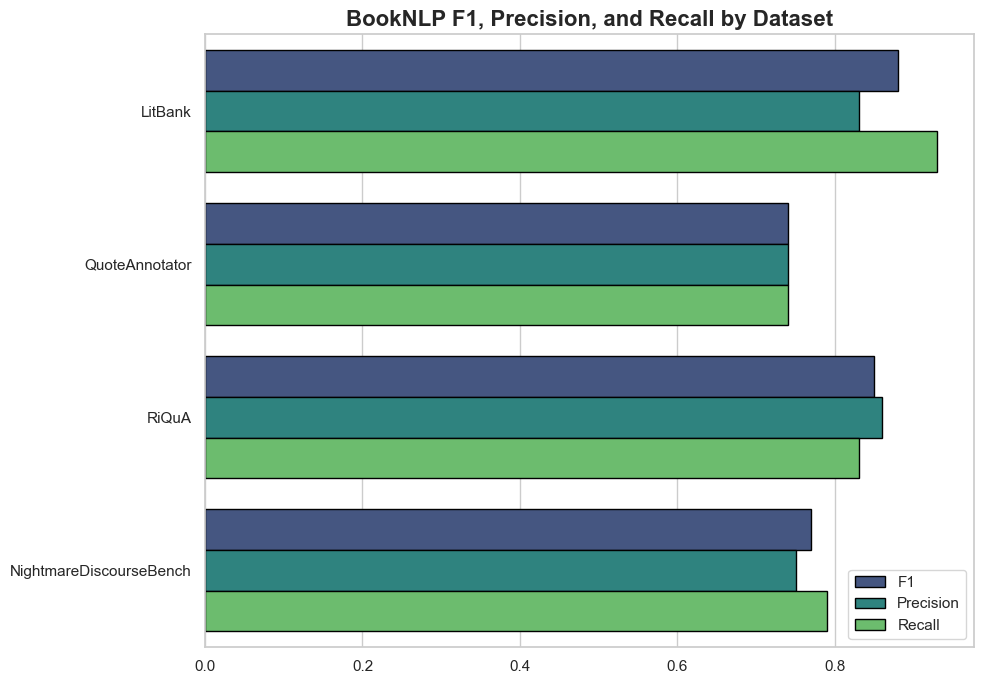

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Make sure the metric rows are the index
# table = table.set_index("Unnamed: 0")

metric_rows = ["Mean F1", "Mean Precision", "Mean Recall"]
metric_df = table.loc[metric_rows].T.copy()

# Rename columns to cleaner labels
metric_df = metric_df.rename(columns={
    "Mean F1": "F1",
    "Mean Precision": "Precision",
    "Mean Recall": "Recall"
}, index={"NDB": "NightmareDiscourseBench"})

# Keep dataset names and turn metric columns to long form
plot_df = metric_df.reset_index().rename(columns={"index": "Dataset"})
plot_df = plot_df.melt(
    id_vars="Dataset",
    var_name="Metric",
    value_name="Score"
)

plot_df["Score"] = pd.to_numeric(plot_df["Score"], errors="coerce")
plot_df = plot_df.dropna(subset=["Score"])

# Order datasets by F1 descending
f1_order = (
    metric_df["F1"]
    .astype(float)
    .index
)

plot_df["Dataset"] = pd.Categorical(
    plot_df["Dataset"],
    categories=f1_order,
    ordered=True
)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 7))

metric_colors = dict(zip(
    ["F1", "Precision", "Recall"],
    sns.color_palette("viridis", 3)
))

sns.barplot(
    data=plot_df,
    x="Score",
    y="Dataset",
    hue="Metric",
    palette=metric_colors,
    dodge=True,
    edgecolor="black",
    ax=ax
)

ax.set_title("BookNLP F1, Precision, and Recall by Dataset", fontsize=16, weight="bold")
ax.set_xlabel(None)
ax.set_ylabel(None)
ax.legend(title=None)
plt.tight_layout()
plt.savefig("chr_graphs/accuracy_graph.png")
plt.show()

In [ ]:
latex_table = table.to_latex(
    index=False,          # avoid accidental extra index column
    escape=True,          # escape &, %, _, etc.
    caption="Example table and table caption.",
    label="tab:example",
    position="h",
    column_format="cc"    # must match number of DataFrame columns
)
print(latex_table)

with open("chr_graphs/latex_table_code.txt", "w") as f:
    f.write(latex_table)


\begin{table}[h]
\caption{Example table and table caption.}
\label{tab:example}
\begin{tabular}{cc}
\toprule
LitBank & QuoteAnnotator & RiQuA & NDB \\
\midrule
0.880000 & 0.740000 & 0.850000 & 0.770000 \\
0.380000 & 0.240000 & 0.160000 & 0.280000 \\
0.830000 & 0.740000 & 0.860000 & 0.750000 \\
0.380000 & 0.230000 & 0.160000 & 0.280000 \\
0.930000 & 0.740000 & 0.830000 & 0.790000 \\
0.410000 & 0.250000 & 0.180000 & 0.270000 \\
\bottomrule
\end{tabular}
\end{table}



/var/folders/2_/h5fmwrys01j7gg7gfbvsslfr0000gq/T/ipykernel_1277/1440614823.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


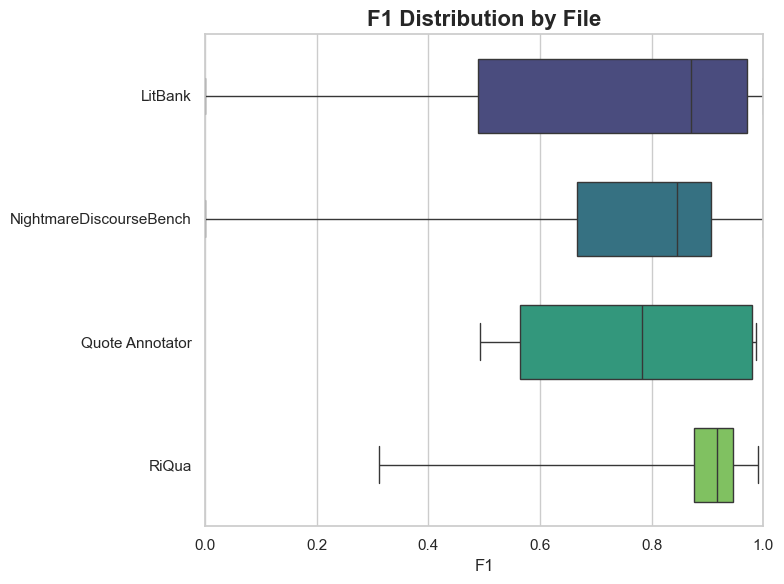

In [ ]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

folder = "/Users/claudiac/Library/CloudStorage/GoogleDrive-ccarrol2@andrew.cmu.edu/Shared drives/ccarrol2 Research/dialogue/booknlp_test"

records = []

for file in sorted(os.listdir(folder)):
    if not file.endswith(".xlsx"):
        continue
    if "comparison" in file.lower():
        continue

    file_path = os.path.join(folder, file)
    df = pd.read_excel(file_path)

    f1_col = next((c for c in df.columns if str(c).strip().lower() == "f1"), None)
    if f1_col is None:
        continue

    vals = pd.to_numeric(df[f1_col], errors="coerce").dropna()
    if vals.empty:
        continue

    for v in vals:
        records.append({
            "File": os.path.splitext(file)[0],
            "F1": float(v)
        })

plot_df = pd.DataFrame(records)

custom_labels = {
    "booknlp_litbank": "LitBank",
    "booknlp_nightmare": "NightmareDiscourseBench",
    "booknlp_riqua": "RiQua",
    "booknlp_quoteannotator": "Quote Annotator"

}

plot_df["File"] = plot_df["File"].map(custom_labels).fillna(plot_df["File"])

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, max(6, len(plot_df["File"].unique()) * 0.5)))

sns.boxplot(
    data=plot_df,
    y="File",
    x="F1",
    palette="viridis",
    width=0.6,
    showfliers=True,
    whis=10,
    ax=ax
)

ax.set_title("F1 Distribution by File", fontsize=16, fontweight="bold")
ax.set_xlabel("F1", fontsize=12)
ax.set_ylabel(None)
ax.set_xlim(0, 1)
plt.tight_layout()
plt.savefig("chr_graphs/f1_boxplot.png")
plt.show()

/var/folders/2_/h5fmwrys01j7gg7gfbvsslfr0000gq/T/ipykernel_1277/2390912725.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


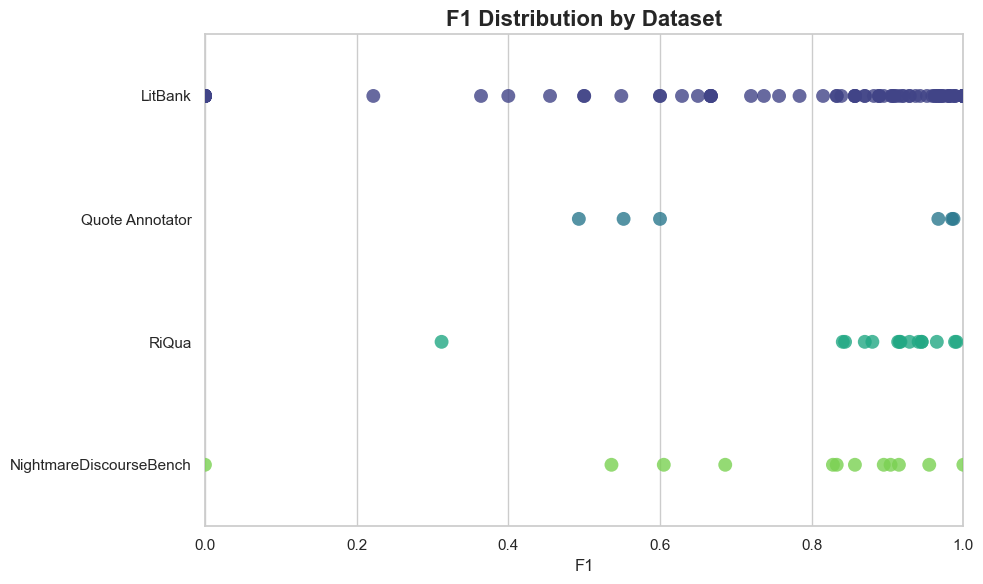

In [ ]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

folder = "/Users/claudiac/Library/CloudStorage/GoogleDrive-ccarrol2@andrew.cmu.edu/Shared drives/ccarrol2 Research/dialogue/booknlp_test"

records = []

for file in sorted(os.listdir(folder)):
    if not file.endswith(".xlsx"):
        continue
    if "comparison" in file.lower():
        continue

    file_path = os.path.join(folder, file)
    df = pd.read_excel(file_path)

    f1_col = next((c for c in df.columns if str(c).strip().lower() == "f1"), None)
    if f1_col is None:
        continue

    vals = pd.to_numeric(df[f1_col], errors="coerce").dropna()
    if vals.empty:
        continue

    dataset_name = os.path.splitext(file)[0]

    for v in vals:
        records.append({
            "Dataset": dataset_name,
            "F1": float(v)
        })

plot_df = pd.DataFrame(records)

custom_labels = {
    "booknlp_litbank": "LitBank",
    "booknlp_nightmare": "NightmareDiscourseBench",
    "booknlp_riqua": "RiQua",
    "booknlp_quoteannotator": "Quote Annotator"
}
plot_df["Dataset"] = plot_df["Dataset"].map(custom_labels).fillna(plot_df["Dataset"])

order = [
    "LitBank",
    "Quote Annotator",
    "RiQua",
    "NightmareDiscourseBench"
]

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

sns.stripplot(
    data=plot_df,
    y="Dataset",
    x="F1",
    order=order,
    jitter=False,
    size=10,
    alpha=0.8,
    palette="viridis",
    ax=ax
)

ax.set_title("F1 Distribution by Dataset", fontsize=16, fontweight="bold")
ax.set_xlabel("F1", fontsize=12)
ax.set_ylabel(None)
ax.set_xlim(0, 1)
plt.tight_layout()
plt.savefig("chr_graphs/dot_plot.png")
plt.show()